<a href="https://colab.research.google.com/github/MikorzPL/BioML/blob/main/MPNN_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BioML Assignment: Molecule logP Prediction using MPNNs
        
This assignment investigates the application of a Message Passing Neural Network (MPNN) for predicting the partition coefficient (logP) of chemical compounds based on their SMILES representations. Specifically, I have focused on evaluating the impact of different aggregation functions—sum, mean, and max—within the graph neural network's layers.

# Install dependencies

In [ ]:
!pip install numpy rdkit torch
!pip install torch-geometric

import numpy as np
import torch
import torch_geometric
from rdkit import Chem

print(f"Torch version: {torch.__version__}")
print(f"PyG version: {torch_geometric.__version__}")

Torch version: 2.11.0+cu128
PyG version: 2.8.0.post1


# Data loading

In [ ]:
import requests

data_url = "https://raw.githubusercontent.com/dgront/chem-ml/refs/heads/main/INPUTS/xlogp_JChemEdu/xlogp.tsv"
response = requests.get(data_url)
data_rows = []

# Skip the first row (header)
for line in response.text.splitlines()[1:]:
    columns = line.split("\t")
    if len(columns) == 4:
        # Skip rows where the SMILES string (index 2) is empty
        if len(columns[2]) == 0:
            continue
        data_rows.append(columns)

print("First 5 rows:")
for row in data_rows[:5]:
    print(row)

print(f"\nTotal rows: {len(data_rows)}")

First 5 rows:
['1-Aminopropan-2-ol', 'C3H9NO', 'CC(CN)O', '-1']
['"1-Chloro-2,4-dinitrobenzene"', 'C6H3ClN2O4', 'C1=CC(=C(C=C1[N+](=O)[O-])[N+](=O)[O-])Cl', '2.3']
['9-Ethyladenine', 'C7H9N5', 'CCN1C=NC2=C(N=CN=C21)N', '0.2']
['"1,2-Dichloroethane"', 'C2H4Cl2', 'C(CCl)Cl', '1.5']
['"1,2,4-Trichlorobenzene"', 'C6H3Cl3', 'C1=CC(=C(C=C1Cl)Cl)Cl', '4']

Total rows: 266711


# Define a function that extracts features

In [ ]:
def featurize_from_smiles(smiles):
    """
    Converts a SMILES string into basic data structures for MPNN training.
    Returns None if sanitization fails (e.g. valence errors).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print(f"Retrieving the molecule failed for SMILES {smiles}")
        return None

    try:
        # Add hydrogens and perform sanitization
        mol = Chem.AddHs(mol)
        Chem.SanitizeMol(mol)
    except ValueError as e:
        # Catches valence errors or other chemical inconsistencies
        print(f"Sanitization failed for SMILES {smiles}: {e}")
        return None

    # Atom features
    elements = []
    hybridizations = []
    aromaticity = []
    formal_charges = []
    chirality = []

    for atom in mol.GetAtoms():
        elements.append(atom.GetSymbol())
        hybridizations.append(str(atom.GetHybridization()))
        aromaticity.append(1 if atom.GetIsAromatic() else 0)
        formal_charges.append(atom.GetFormalCharge())
        chirality.append(str(atom.GetChiralTag()))

    # Bond features
    bonds = []
    for bond in mol.GetBonds():
        begin_idx = bond.GetBeginAtomIdx()
        end_idx = bond.GetEndAtomIdx()
        bond_type = str(bond.GetBondType())
        is_conjugated = int(bond.GetIsConjugated())
        bonds.append((begin_idx, end_idx, bond_type, is_conjugated))

    return elements, hybridizations, bonds, aromaticity, formal_charges, chirality


# --- Example: Process first record ---
print("Example for first record:")
single_smiles = data_rows[0][2]
features = featurize_from_smiles(single_smiles)
if features:
    elements, hybridizations, bonds, aromaticity, formal_charges, chirality = features
    print(f"SMILES: {single_smiles}")
    print(f"Elements: {elements}")
    print(f"Bonds: {bonds[:3]}... (showing first 3)")

Example for first record:
SMILES: CC(CN)O
Elements: ['C', 'C', 'C', 'N', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H']
Bonds: [(0, 1, 'SINGLE', 0), (1, 2, 'SINGLE', 0), (2, 3, 'SINGLE', 0)]... (showing first 3)


# One-hot encoding

In [ ]:
allowed_bond_types    = ['SINGLE', 'DOUBLE', 'TRIPLE', 'AROMATIC']
allowed_elements      = ['C', 'N', 'O', 'H', 'Cl', 'P', 'S', 'As', 'Br', 'Ca', 'Se', 'I', 'K', 'Mg', 'Na', 'Ni', 'W', 'F', 'B', 'Hg', 'Al', 'Li', 'Zn', 'Si', 'Co', 'Pb', 'Sn', 'Cu', 'Ba', 'Fe', 'Mn', 'Cr']
allowed_hybridization = ['SP', 'SP2', 'SP3', 'SP3D', 'SP3D2', 'S', 'UNSPECIFIED']
allowed_chirality     = ['CHI_UNSPECIFIED', 'CHI_TETRAHEDRAL_CW', 'CHI_TETRAHEDRAL_CCW', 'CHI_OTHER']

# Create mapping dictionaries
allowed_bond_indexed          = {t: i for i, t in enumerate(allowed_bond_types)}
allowed_elements_indexed      = {t: i for i, t in enumerate(allowed_elements)}
allowed_hybridization_indexed = {t: i for i, t in enumerate(allowed_hybridization)}
allowed_chirality_indexed     = {t: i for i, t in enumerate(allowed_chirality)}

def one_hot_encode(value, indexed_dict):
    """
    Creates a one-hot encoded numpy array using a predefined indexed dictionary.
    If the value is not found, it puts 1.0 in the last index.
    """
    vector = np.zeros(len(indexed_dict) + 1, dtype=np.float32)
    # Use .get() to find index, defaulting to the last position if key is missing
    idx = indexed_dict.get(value, len(indexed_dict))
    vector[idx] = 1.0
    return vector

# Example usage:
element_vector = one_hot_encode('UnknownElement', allowed_elements_indexed)
print(f"Vector for unknown element: {element_vector}")
print(f"Last index is 1: {element_vector[-1] == 1.0}")

Vector for unknown element: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Last index is 1: True


# Calculate features

In [ ]:
import numpy as np
import torch
from tqdm import tqdm
from torch_geometric.data import Data

def process_molecule(row):
    """
    Processes a single row of chemical data into a PyTorch Geometric Data object.
    """
    name, formula, smiles, logp_str = row

    if logp_str == 'NULL':
        return None

    try:
        logp_val = float(logp_str)
    except ValueError:
        return None

    features = featurize_from_smiles(smiles)
    if features is None:
        return None

    elements, hybridizations, bonds, aromaticity, formal_charges, chirality = features

    # Atom features encoding
    node_features = []
    for i in range(len(elements)):
        atom_vector = np.concatenate([
            one_hot_encode(elements[i], allowed_elements_indexed),
            one_hot_encode(hybridizations[i], allowed_hybridization_indexed),
            [float(aromaticity[i])],
            [float(formal_charges[i])],
            one_hot_encode(chirality[i], allowed_chirality_indexed)
        ])
        node_features.append(atom_vector)

    # Bond features encoding
    edge_indices = []
    edge_attributes = []
    for start, end, bond_type, conjugation in bonds:
        bond_vector = np.concatenate([
            one_hot_encode(bond_type, allowed_bond_indexed),
            [float(conjugation)]
        ])
        edge_indices.append([start, end])
        edge_attributes.append(bond_vector)
        edge_indices.append([end, start])
        edge_attributes.append(bond_vector)

    return Data(
        x=torch.tensor(np.array(node_features), dtype=torch.float),
        edge_index=torch.tensor(np.array(edge_indices).T, dtype=torch.long),
        edge_attr=torch.tensor(np.array(edge_attributes), dtype=torch.float),
        y=torch.tensor([logp_val], dtype=torch.float),
        name=name,
        formula=formula,
        smiles=smiles
    )

# Configuration
max_to_process = 100000
subset_rows = data_rows[:max_to_process]

print(f"Processing {len(subset_rows)} molecules in a single process to save memory...")

all_features = []
failed_count = 0

for row in tqdm(subset_rows, desc="Featurizing"):
    res = process_molecule(row)
    if res is not None:
        all_features.append(res)
    else:
        failed_count += 1

print(f"\nSuccessfully processed: {len(all_features)} molecules")
print(f"Skipped/Failed: {failed_count} molecules")
if len(all_features) > 0:
    print(f"Example PyG Data object: {all_features[0]}")

Processing 100000 molecules in a single process to save memory...


Featurizing:  10%|█         | 10046/100000 [00:16<01:34, 947.60it/s][12:52:25] Explicit valence for atom # 1 Br, 3, is greater than permitted
[12:52:25] Explicit valence for atom # 1 Br, 5, is greater than permitted
[12:52:25] Explicit valence for atom # 1 Cl, 3, is greater than permitted
Featurizing:  10%|█         | 10234/100000 [00:16<01:13, 1213.82it/s]

Retrieving the molecule failed for SMILES O=Cl(=O)(=O)F
Retrieving the molecule failed for SMILES FBr(F)F
Retrieving the molecule failed for SMILES FBr(F)(F)(F)F
Retrieving the molecule failed for SMILES FCl(F)F


Featurizing:  14%|█▎        | 13626/100000 [00:21<01:28, 972.07it/s]

Retrieving the molecule failed for SMILES FCl(F)(F)(F)F


Featurizing:  19%|█▉        | 19421/100000 [00:26<01:03, 1269.96it/s]

Retrieving the molecule failed for SMILES FI(F)(F)(F)(F)(F)F


Featurizing:  27%|██▋       | 26797/100000 [00:35<01:08, 1064.08it/s][12:52:44] WARNING: not removing hydrogen atom without neighbors
[12:52:44] WARNING: not removing hydrogen atom without neighbors
Featurizing: 100%|██████████| 100000/100000 [02:21<00:00, 706.00it/s]


Successfully processed: 91728 molecules
Skipped/Failed: 8272 molecules
Example PyG Data object: Data(x=[14, 48], edge_index=[2, 26], edge_attr=[26, 6], y=[1], name='1-Aminopropan-2-ol', formula='C3H9NO', smiles='CC(CN)O')


# Split the data into training, validation and test sets


In [ ]:
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
random_seed = 42

# First split: 70% train, 30% for validation + test
train_data, temp_data = train_test_split(
    all_features,
    test_size=0.3,
    random_state=random_seed
)

# Second split: split the 30% into half validation (10% total) and half test (10% total)
validation_data, test_data = train_test_split(
    temp_data,
    test_size=0.5,
    random_state=random_seed
)

print(f"Dataset splitting complete:")
print(f"- Training set:   {len(train_data)} molecules")
print(f"- Validation set: {len(validation_data)} molecules")
print(f"- Test set:       {len(test_data)} molecules")

Dataset splitting complete:
- Training set:   64209 molecules
- Validation set: 13759 molecules
- Test set:       13760 molecules


# Create data loaders

In [ ]:
from torch_geometric.loader import DataLoader

# Define batch size
batch_size = 64

# Create DataLoaders for each split
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

print(f"DataLoaders created successfully:")
print(f"- Train loader: {len(train_loader)} batches")
print(f"- Validation loader: {len(validation_loader)} batches")
print(f"- Test loader: {len(test_loader)} batches")

# Inspect the first batch from the train loader
for batch in train_loader:
    print(f"\nExample batch info:")
    print(f"Batch size: {batch.num_graphs}")
    print(f"Total nodes in batch: {batch.x.shape[0]}")
    print(f"Target shape: {batch.y.shape}")
    break

DataLoaders created successfully:
- Train loader: 1004 batches
- Validation loader: 215 batches
- Test loader: 215 batches

Example batch info:
Batch size: 64
Total nodes in batch: 2471
Target shape: torch.Size([64])


# Define MPNN model architecture




In [ ]:
import torch
import torch.nn.functional
from torch.nn import Sequential, Linear, ReLU
from torch_geometric.nn import NNConv, global_add_pool

class MPNNModel(torch.nn.Module):
    def __init__(self, node_input_dimension=48, edge_input_dimension=6, hidden_dimension=64, dropout_rate=0.1, aggregation_1='sum', aggregation_2='mean'):
        super().__init__()

        self.dropout_rate = dropout_rate

        # Auxiliary sequential layer
        edge_neural_network_1 = Sequential(
            Linear(in_features=edge_input_dimension, out_features=128),
            ReLU(),
            Linear(in_features=128, out_features=node_input_dimension * hidden_dimension)
        )

        # First message passing layer
        self.message_passing_layer_1 = NNConv(
            in_channels=node_input_dimension,
            out_channels=hidden_dimension,
            nn=edge_neural_network_1,
            aggr=aggregation_1
        )

        # Second message passing layer
        edge_neural_network_2 = Sequential(
            Linear(in_features=edge_input_dimension, out_features=128),
            ReLU(),
            Linear(in_features=128, out_features=hidden_dimension * hidden_dimension)
        )

        self.message_passing_layer_2 = NNConv(
            in_channels=hidden_dimension,
            out_channels=hidden_dimension,
            nn=edge_neural_network_2,
            aggr=aggregation_2
        )

        # Prediction layers (Standard Linear layers)
        self.linear_prediction_layer_1 = Linear(in_features=hidden_dimension, out_features=32)
        self.linear_prediction_layer_2 = Linear(in_features=32, out_features=1)

    def forward(self, data):
        atoms_vector = data.x
        connections_map = data.edge_index
        bond_features_vector = data.edge_attr
        molecule_batch_map = data.batch

        # First Message Passing Phase
        atoms_vector = self.message_passing_layer_1(x=atoms_vector, edge_index=connections_map, edge_attr=bond_features_vector)
        atoms_vector = torch.nn.functional.relu(atoms_vector)

        # Second Message Passing Phase
        atoms_vector = self.message_passing_layer_2(x=atoms_vector, edge_index=connections_map, edge_attr=bond_features_vector)
        atoms_vector = torch.nn.functional.relu(atoms_vector)

        # Readout Phase (Global Pooling)
        entire_molecule_vector = global_add_pool(x=atoms_vector, batch=molecule_batch_map)

        # Prediction Phase (with Dropout)
        final_prediction = self.linear_prediction_layer_1(entire_molecule_vector)
        final_prediction = torch.nn.functional.relu(final_prediction)

        final_prediction = torch.nn.functional.dropout(final_prediction, p=self.dropout_rate, training=self.training)

        final_prediction = self.linear_prediction_layer_2(final_prediction)

        return final_prediction.flatten()

# Reusable training loop and test function

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def train_and_test_experiment(aggregation_1, aggregation_2, train_loader, validation_loader, test_loader, epochs=100):

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    print(f"--- Starting experiment with Aggr_1: {aggregation_1.upper()} | Aggr_2: {aggregation_2.upper()} ---")

    # Initialize model with specific aggregation methods
    model = MPNNModel(aggregation_1=aggregation_1, aggregation_2=aggregation_2).to(device)
    loss_function = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_mse_history = []
    val_mse_history = []

    # Training loop
    for epoch in range(epochs):

        # Training Phase
        model.train()
        total_train_loss = 0

        for batch in train_loader:

            batch = batch.to(device)

            optimizer.zero_grad()
            predictions = model(batch)
            loss = loss_function(predictions, batch.y)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * batch.num_graphs

        # Calculate the average error across all molecules in the training set and save it
        average_train_loss = total_train_loss / len(train_loader.dataset)
        train_mse_history.append(average_train_loss)

        # Validation Phase
        model.eval()
        total_val_loss = 0

        with torch.no_grad():
            for batch in validation_loader:
                batch = batch.to(device)

                predictions = model(batch)
                loss = loss_function(predictions, batch.y)

                total_val_loss += loss.item() * batch.num_graphs

        # Calculate the average error across all molecules in the validation set and save it
        average_val_loss = total_val_loss / len(validation_loader.dataset)
        val_mse_history.append(average_val_loss)

        # Print the progress
        print(f"Epoch {epoch+1:02d} | Train Loss (MSE): {average_train_loss:.4f} | Validation Loss (MSE): {average_val_loss:.4f}")

    # Testing Phase
    model.eval()
    total_test_loss = 0
    all_predictions = []
    all_true_values = []

    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            predictions = model(batch)
            loss = loss_function(predictions, batch.y)
            total_test_loss += loss.item() * batch.num_graphs

            # Move data back to CPU and save it to the lists
            all_predictions.extend(predictions.cpu().numpy())
            all_true_values.extend(batch.y.cpu().numpy())

    # Calculate final average error (MSE)
    average_test_loss = total_test_loss / len(test_loader.dataset)
    print(f"Final Test Loss (MSE) on Unseen Data: {average_test_loss:.4f}")

    # Calculate MAE
    mae = np.mean(np.abs(np.array(all_predictions) - np.array(all_true_values)))
    print(f"Final Test MAE on Unseen Data: {mae:.4f}")

    return average_test_loss, mae, train_mse_history, val_mse_history

# Run experiment on different combinations of aggregation methods


In [ ]:
# List of aggregation combinations to test (layer 1, layer 2)
combinations = [
    ('sum', 'sum'),
    ('sum', 'mean'),
    ('sum', 'max'),
    ('mean', 'sum'),
    ('mean', 'mean'),
    ('mean', 'max'),
    ('max', 'sum'),
    ('max', 'mean'),
    ('max', 'max')
]

# Create dictionaries to store the final results and history of learning curve
experiment_results = {}
history_results = {}

# Run for 100 epochs
for aggr_1, aggr_2 in combinations:
    label = f"{aggr_1} & {aggr_2}"

    final_mse, final_mae, train_hist, val_hist = train_and_test_experiment(
        aggregation_1=aggr_1,
        aggregation_2=aggr_2,
        train_loader=train_loader,
        validation_loader=validation_loader,
        test_loader=test_loader,
        epochs=100
    )

    experiment_results[label] = {'MSE': final_mse, 'MAE': final_mae}
    history_results[label] = {'train': train_hist, 'val': val_hist}

Using device: cuda
--- Starting experiment with Aggr_1: SUM | Aggr_2: SUM ---
Epoch 01 | Train Loss (MSE): 1.0794 | Validation Loss (MSE): 0.3367
Epoch 02 | Train Loss (MSE): 0.4833 | Validation Loss (MSE): 0.2039
Epoch 03 | Train Loss (MSE): 0.4280 | Validation Loss (MSE): 0.2343
Epoch 04 | Train Loss (MSE): 0.3841 | Validation Loss (MSE): 0.2131
Epoch 05 | Train Loss (MSE): 0.3714 | Validation Loss (MSE): 0.2039
Epoch 06 | Train Loss (MSE): 0.3424 | Validation Loss (MSE): 0.1634
Epoch 07 | Train Loss (MSE): 0.3440 | Validation Loss (MSE): 0.1466
Epoch 08 | Train Loss (MSE): 0.3321 | Validation Loss (MSE): 0.2068
Epoch 09 | Train Loss (MSE): 0.3138 | Validation Loss (MSE): 0.1401
Epoch 10 | Train Loss (MSE): 0.2927 | Validation Loss (MSE): 0.1301
Epoch 11 | Train Loss (MSE): 0.2932 | Validation Loss (MSE): 0.1464
Epoch 12 | Train Loss (MSE): 0.2850 | Validation Loss (MSE): 0.1353
Epoch 13 | Train Loss (MSE): 0.2641 | Validation Loss (MSE): 0.1134
Epoch 14 | Train Loss (MSE): 0.2551 | 

/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Epoch 01 | Train Loss (MSE): 0.9633 | Validation Loss (MSE): 0.7796
Epoch 02 | Train Loss (MSE): 0.4624 | Validation Loss (MSE): 0.2416
Epoch 03 | Train Loss (MSE): 0.4018 | Validation Loss (MSE): 0.1857
Epoch 04 | Train Loss (MSE): 0.3610 | Validation Loss (MSE): 0.2288
Epoch 05 | Train Loss (MSE): 0.3395 | Validation Loss (MSE): 0.1667
Epoch 06 | Train Loss (MSE): 0.3274 | Validation Loss (MSE): 0.1473
Epoch 07 | Train Loss (MSE): 0.3048 | Validation Loss (MSE): 0.2913
Epoch 08 | Train Loss (MSE): 0.2920 | Validation Loss (MSE): 0.1456
Epoch 09 | Train Loss (MSE): 0.2685 | Validation Loss (MSE): 0.1219
Epoch 10 | Train Loss (MSE): 0.2553 | Validation Loss (MSE): 0.1320
Epoch 11 | Train Loss (MSE): 0.2398 | Validation Loss (MSE): 0.1376
Epoch 12 | Train Loss (MSE): 0.2329 | Validation Loss (MSE): 0.1203
Epoch 13 | Train Loss (MSE): 0.2234 | Validation Loss (MSE): 0.1156
Epoch 14 | Train Loss (MSE): 0.2082 | Validation Loss (MSE): 0.1041
Epoch 15 | Train Loss (MSE): 0.1885 | Validation

# Plot learning curves

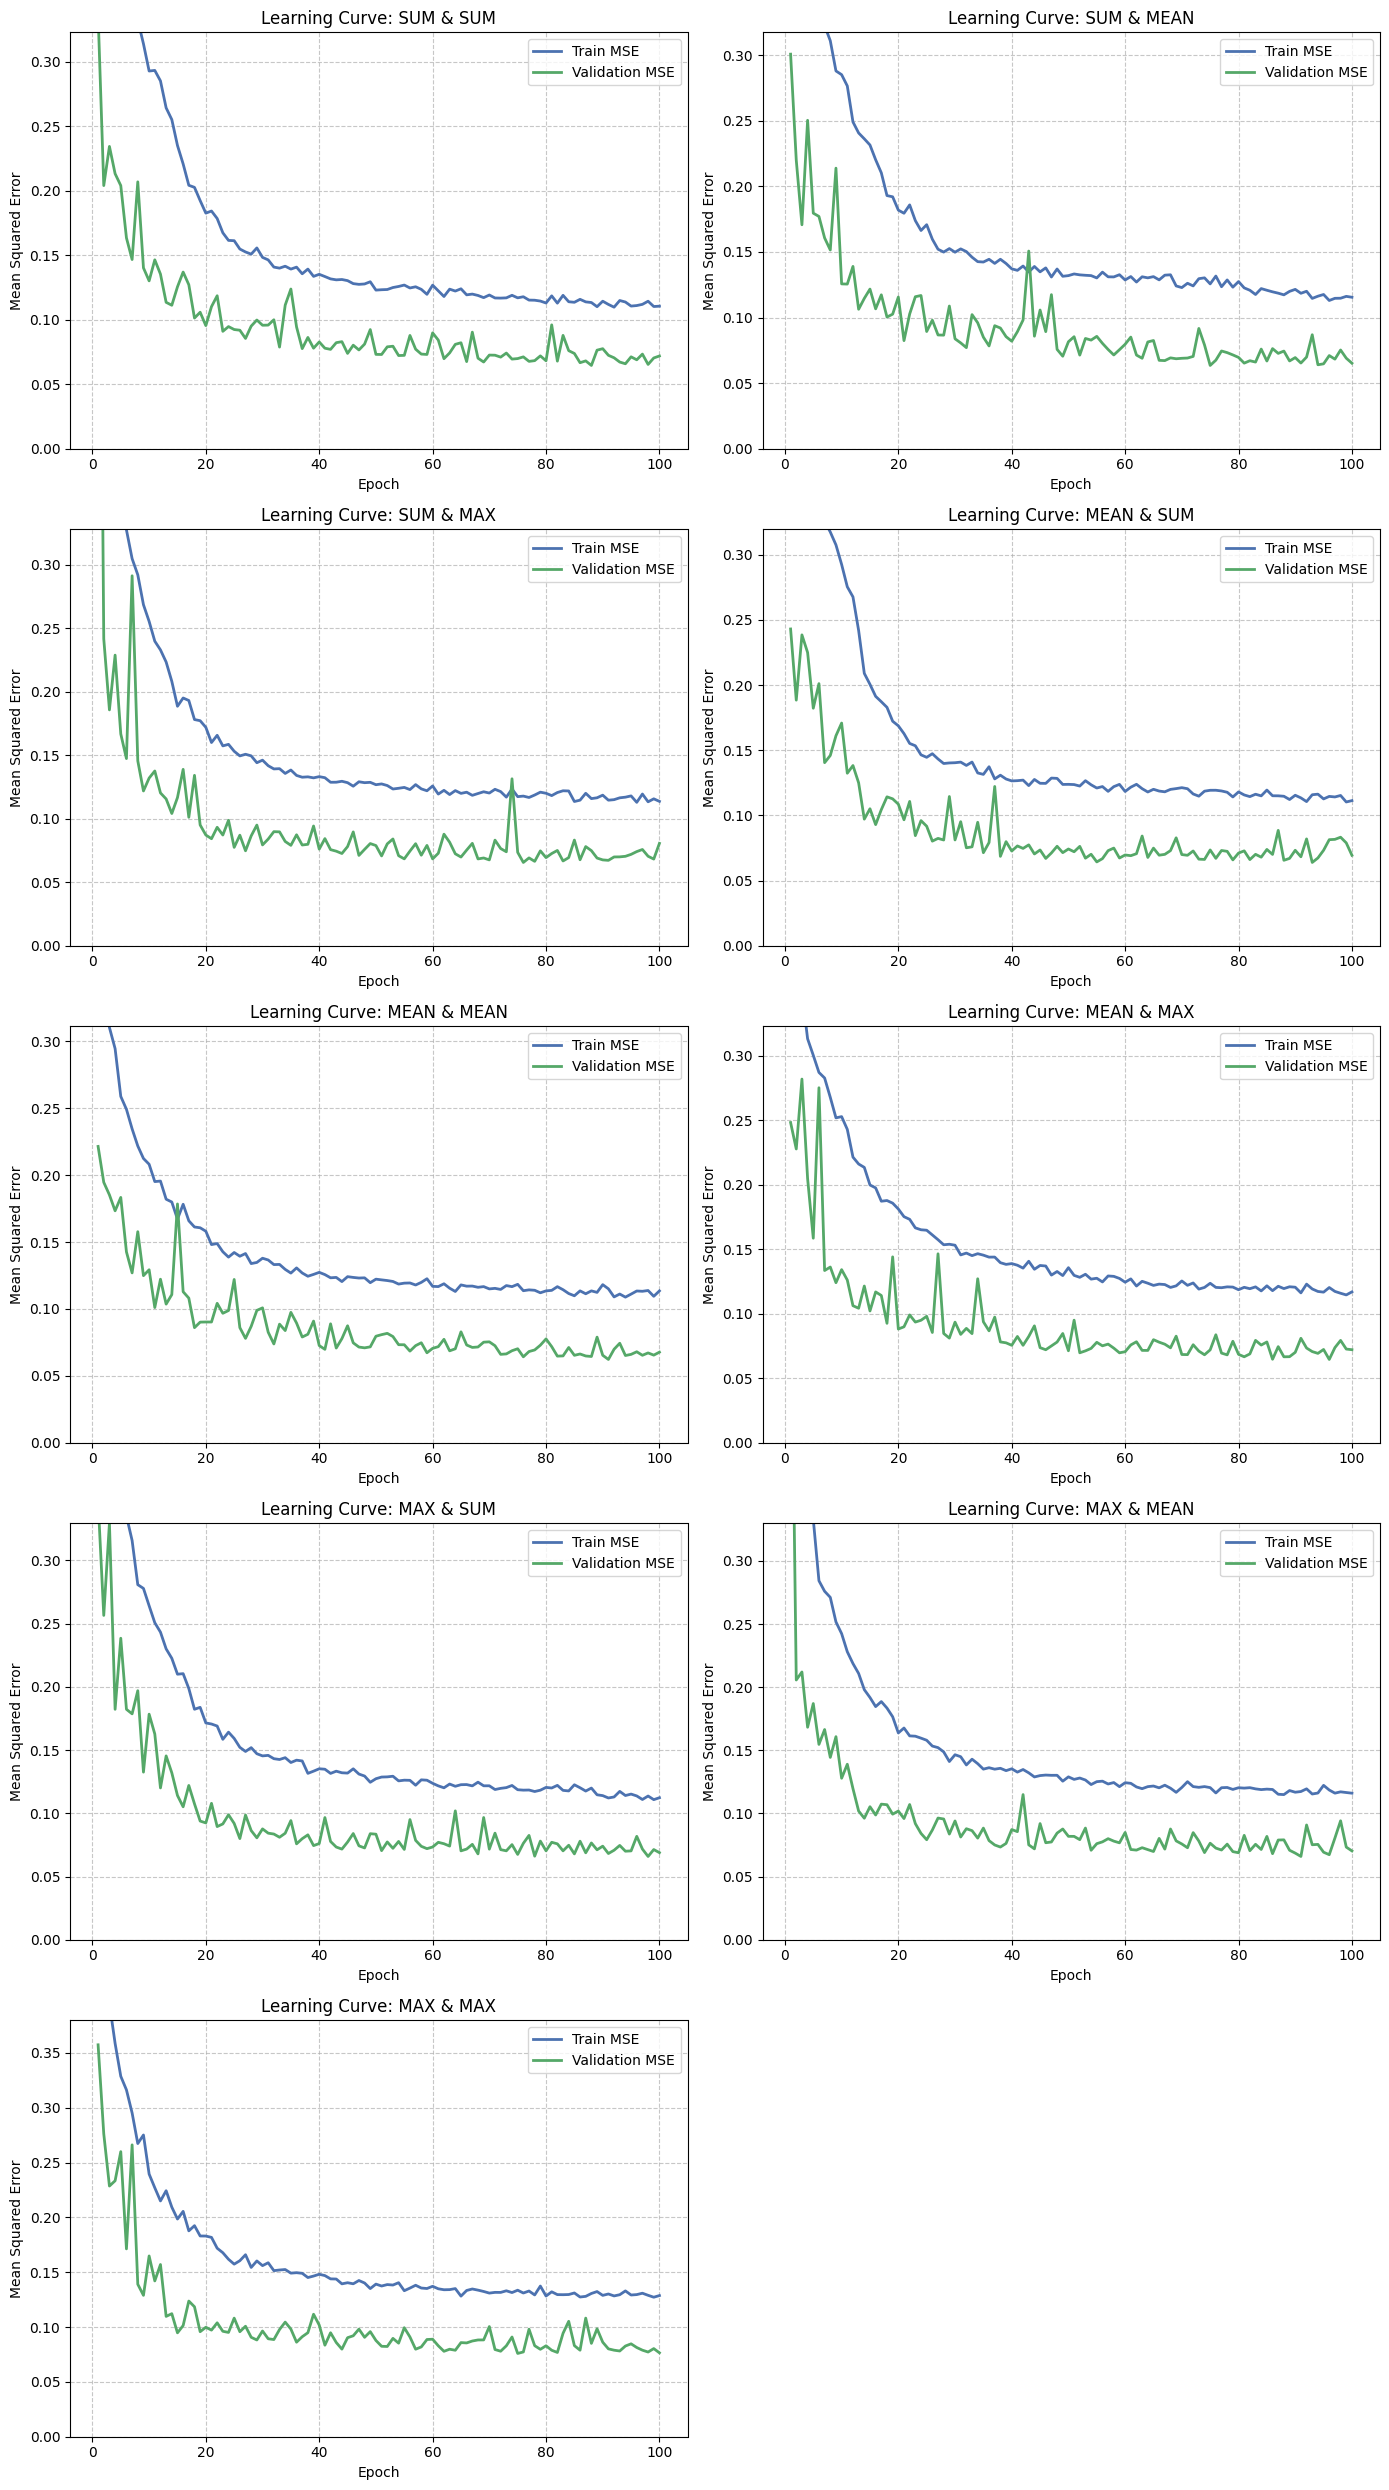

In [ ]:
import math
import matplotlib.pyplot as plt

def plot_learning_curves(history_dict):
    """
    Plots learning curves (Train vs Validation MSE) dynamically based on the
    number of experiments in the provided dictionary.
    """
    num_plots = len(history_dict)
    cols = 2
    # Dynamically calculate rows needed
    rows = math.ceil(num_plots / cols)

    # Adjust figure size based on the number of rows
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5 * rows))

    # Ensure axes is always a flat iterable, even for a single plot or single row
    if num_plots == 1:
        axes = [axes] if rows == 1 and cols == 1 else axes.flatten()
    else:
        axes = axes.flatten()

    # Track the last used index to hide empty subplots later
    last_idx = -1

    for i, (label, hist) in enumerate(history_dict.items()):
        ax = axes[i]
        epochs_range = range(1, len(hist['train']) + 1)

        ax.plot(epochs_range, hist['train'], label='Train MSE', color='#4C72B0', linewidth=2)
        ax.plot(epochs_range, hist['val'], label='Validation MSE', color='#55A868', linewidth=2)

        ax.set_title(f'Learning Curve: {label.upper()}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Mean Squared Error')
        ax.legend()
        ax.grid(True, linestyle='--', alpha=0.7)

        # Dynamically scale Y-axis to ignore initial massive spikes
        val_min = min(hist['val'])
        ax.set_ylim(0, val_min * 5)

        last_idx = i

    # Hide any unused subplots if the grid has empty slots
    for j in range(last_idx + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


plot_learning_curves(history_results)

# Compare results

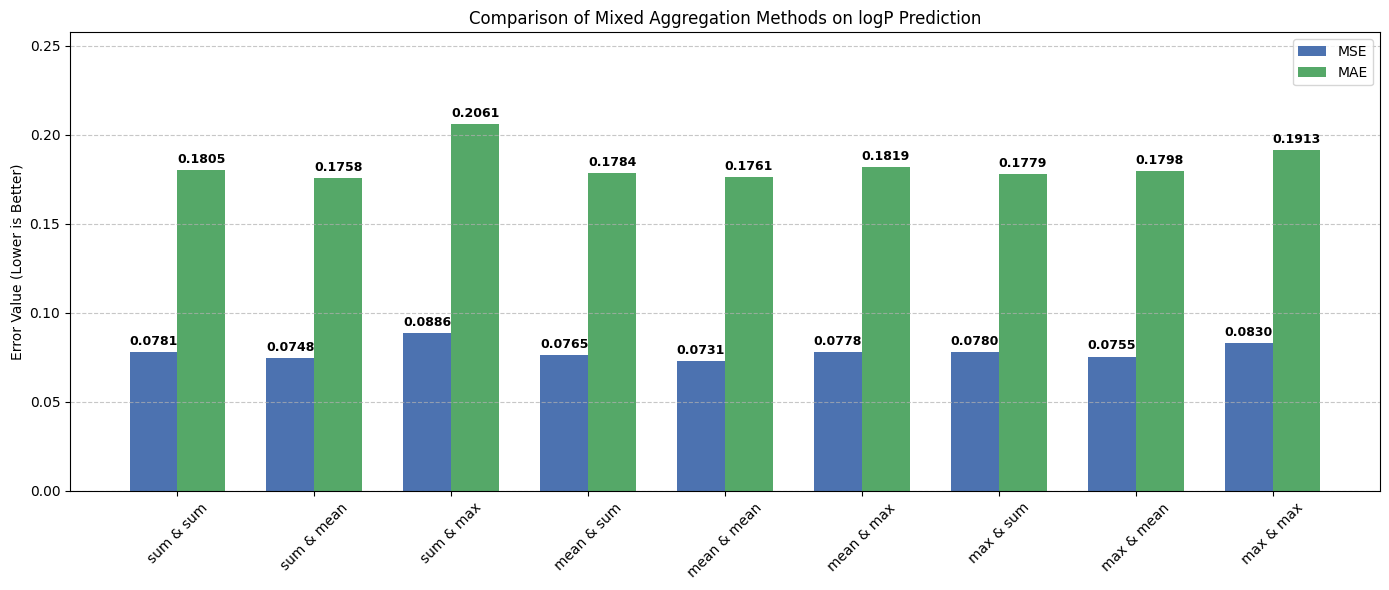

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data for plotting
labels = list(experiment_results.keys())
mse_values = [results['MSE'] for results in experiment_results.values()]
mae_values = [results['MAE'] for results in experiment_results.values()]

x = np.arange(len(labels))
width = 0.35

# Increased figure width to accommodate 9 combinations
fig, ax = plt.subplots(figsize=(14, 6))

# Create grouped bars
bars_mse = ax.bar(x - width/2, mse_values, width, label='MSE', color='#4C72B0')
bars_mae = ax.bar(x + width/2, mae_values, width, label='MAE', color='#55A868')

ax.set_ylabel('Error Value (Lower is Better)')
ax.set_title('Comparison of Mixed Aggregation Methods on logP Prediction')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45) # Rotated labels to prevent overlapping
ax.legend()

# Function to add text labels on top of the bars
def attach_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

attach_labels(bars_mse)
attach_labels(bars_mae)

# Add space above bars for labels
plt.ylim(0, max(max(mse_values), max(mae_values)) * 1.25)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Conclusion

The results demonstrate that the choice of aggregation method changes how well the MPNN model works and influences its specific error distribution. Looking at both Mean Squared Error (MSE) and Mean Absolute Error (MAE) reveals different results for each architecture:

*   The combination of "mean" and "mean" aggregation achieved the lowest MSE (0.0731) but a slightly higher MAE (0.1761) than the best MAE performer, indicating that it successfully avoids large prediction mistakes but frequently makes smaller ones.
*   On the other hand, the "sum" and "mean" architecture yielded the lowest MAE (0.1758) alongside a higher MSE (0.0748), suggesting it produces highly accurate predictions for typical molecules but occasionally commits significant errors that strongly impact the MSE.
*   The other architectures, especially those using "max" aggregation in the second layer—like sum & max or max & max—performed noticeably worse on both metrics, showing that these setups struggle to learn good molecular representations for this task.